# Fine-Tuning CLIP Sesi 3: Projection-Head Tuning untuk Penebakan Objek Spesifik

### 🎯 Tujuan Eksperimen:
1. **Meningkatkan Akurasi Top-1 Penebakan Objek Spesifik** (Text-to-Image / Image-to-Text Retrieval pada 50 barang Dormiy).
2. **Mencegah Overfitting & Catastrophic Forgetting** dengan teknik **Freeze Backbone**:
   - Kunci 151 juta parameter transformer asli agar pemahaman visual universal CLIP tidak rusak.
   - Hanya latih lapisan `visual_projection` dan `text_projection` (hanya ~0.4% parameter model).
3. **Melihat perkembangan Top-1 & Top-3 per epoch** secara langsung.

--- 
## 1. Import Library & Setup Device

In [1]:
import os
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from transformers import CLIPProcessor, CLIPModel, get_cosine_schedule_with_warmup
from sklearn.model_selection import train_test_split

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device aktif: {str(device).upper()}")

EXPERIMENT_DIR = "experiment_results/sesi_3_projection_head"
os.makedirs(EXPERIMENT_DIR, exist_ok=True)
print(f"Folder eksperimen sesi 3: {EXPERIMENT_DIR}/")

Device aktif: CPU
Folder eksperimen sesi 3: experiment_results/sesi_3_projection_head/


--- 
## 2. Load Dataset Final CV Dormiy (50 Produk Fisik)

In [2]:
manifest_path = "DORMIY-ML-Dataset/data/final/cv/dormiy_cv_manifest.csv"
df_cv = pd.read_csv(manifest_path)

# Buat full path gambar yang kompatibel di Windows/Linux
df_cv['full_image_path'] = df_cv['final_image_path'].apply(
    lambda p: os.path.join("DORMIY-ML-Dataset", p.replace("\\", "/"))
)

print(f"Total Data CV Dormiy: {len(df_cv)} produk")
print("Sample 3 produk:")
df_cv[['product_id', 'title', 'main_category', 'full_image_path']].head(3)

Total Data CV Dormiy: 50 produk
Sample 3 produk:


,product_id,title,main_category,full_image_path
0,prod_0569,WOOD HANDLE LAQ WOOD THRD 15/16 IN X 60,Home & Garden,DORMIY-ML-Dataset\data/final/cv/images/prod_05...
1,prod_0583,"Outvita 7FT Garden Arch Arbor with Seating, He...",Home & Garden,DORMIY-ML-Dataset\data/final/cv/images/prod_05...
2,prod_0659,Elements Ultimate Thin Single Wide Rolling Pap...,Home & Garden,DORMIY-ML-Dataset\data/final/cv/images/prod_06...


--- 
## 3. Evaluasi Murni Baseline Pre-trained CLIP (Sebelum Fine-Tuning)
Menguji: Jika dimasukkan 1 gambar, apakah CLIP bisa menebak judul produk aslinya dari 50 katalog Dormiy?

In [3]:
MODEL_DIR = "clip_model_weights"
print(f"Memuat model pre-trained murni dari: {MODEL_DIR}...")
model = CLIPModel.from_pretrained(MODEL_DIR).to(device)
processor = CLIPProcessor.from_pretrained(MODEL_DIR)
model.eval()

def evaluate_retrieval_performance(eval_model, df_subset, desc="Baseline"):
    eval_model.eval()
    titles = df_subset['title'].tolist()
    
    with torch.no_grad():
        txt_enc = processor(text=titles, return_tensors="pt", padding=True, truncation=True, max_length=77).to(device)
        txt_f = eval_model.get_text_features(**txt_enc)
        txt_f = txt_f.pooler_output if hasattr(txt_f, 'pooler_output') else (txt_f if torch.is_tensor(txt_f) else txt_f[0])
        txt_f = txt_f / txt_f.norm(dim=-1, keepdim=True)

    img_feats = []
    for p in df_subset['full_image_path']:
        img = Image.open(p).convert("RGB")
        inp = processor(images=[img], return_tensors="pt").to(device)
        with torch.no_grad():
            im_out = eval_model.get_image_features(**inp)
            im_f = im_out.pooler_output if hasattr(im_out, 'pooler_output') else (im_out if torch.is_tensor(im_out) else im_out[0])
            im_f = im_f / im_f.norm(dim=-1, keepdim=True)
            img_feats.append(im_f)
    
    img_feats = torch.cat(img_feats, dim=0)
    sim = torch.matmul(img_feats, txt_f.T)
    
    top1, top3, top5 = 0, 0, 0
    total = len(df_subset)
    for i in range(total):
        top_idx = torch.topk(sim[i], k=min(5, total)).indices.cpu().numpy()
        if i == top_idx[0]: top1 += 1
        if i in top_idx[:3]: top3 += 1
        if i in top_idx[:5]: top5 += 1
        
    top1_acc = (top1 / total) * 100
    top3_acc = (top3 / total) * 100
    top5_acc = (top5 / total) * 100
    
    print(f"\n📊 HASIL RETRIEVAL PENEBAKAN OBJEK [{desc}]:")
    print(f"   • Top-1 Product Accuracy : {top1_acc:.2f}% ({top1}/{total} produk persis peringkat 1)")
    print(f"   • Top-3 Product Accuracy : {top3_acc:.2f}% ({top3}/{total} produk masuk di 3 teratas)")
    print(f"   • Top-5 Product Accuracy : {top5_acc:.2f}% ({top5}/{total} produk masuk di 5 teratas)")
    
    return {'top1': top1_acc, 'top3': top3_acc, 'top5': top5_acc}

base_metrics = evaluate_retrieval_performance(model, df_cv, desc="Baseline Murni")

Memuat model pre-trained murni dari: clip_model_weights...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]


📊 HASIL RETRIEVAL PENEBAKAN OBJEK [Baseline Murni]:
   • Top-1 Product Accuracy : 56.00% (28/50 produk persis peringkat 1)
   • Top-3 Product Accuracy : 72.00% (36/50 produk masuk di 3 teratas)
   • Top-5 Product Accuracy : 78.00% (39/50 produk masuk di 5 teratas)


--- 
## 4. Pembagian Data (Train & Val) & PyTorch Dataset

In [4]:
train_df, val_df = train_test_split(
    df_cv,
    test_size=0.2,
    random_state=42,
    stratify=df_cv['main_category']
)

print(f"Data Training : {len(train_df)} produk")
print(f"Data Validasi : {len(val_df)} produk")

class DormiyObjectDataset(Dataset):
    def __init__(self, df, processor):
        self.df = df.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['full_image_path']).convert("RGB")
        title = str(row['title'])[:120]

        encoding = self.processor(
            text=[title],
            images=image,
            padding="max_length",
            max_length=77,
            truncation=True,
            return_tensors="pt"
        )

        return {
            'input_ids': encoding['input_ids'].squeeze(0),
            'attention_mask': encoding['attention_mask'].squeeze(0),
            'pixel_values': encoding['pixel_values'].squeeze(0),
            'product_id': str(row['product_id']),
            'title': str(row['title'])
        }

BATCH_SIZE = 8
train_dataset = DormiyObjectDataset(train_df, processor)
val_dataset = DormiyObjectDataset(val_df, processor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"DataLoader siap! {len(train_loader)} batches training @ batch_size={BATCH_SIZE}")

Data Training : 40 produk
Data Validasi : 10 produk
DataLoader siap! 5 batches training @ batch_size=8


--- 
## 5. Konfigurasi Freeze Backbone & Projection-Head Tuning
Kunci 151 juta bobot transformer, dan buka HANYA lapisan proyeksi visual & teks.

In [5]:
# 1. Bekukan (Freeze) seluruh parameter CLIP
for param in model.parameters():
    param.requires_grad = False

# 2. Buka (Unfreeze) HANYA projection head
for param in model.visual_projection.parameters():
    param.requires_grad = True
for param in model.text_projection.parameters():
    param.requires_grad = True

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print(f"• Total Parameter CLIP      : {total_params:,}")
print(f"• Parameter yang Dilatih    : {trainable_params:,} ({trainable_params/total_params*100:.2f}% saja!)")
print("• Status Backbone           : TERKUNCI AMAN (Mencegah Overfitting & Rusak Bobot)")

# Hyperparameter
EPOCHS = 5
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.01

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=1,
    num_training_steps=len(train_loader) * EPOCHS
)

• Total Parameter CLIP      : 151,277,313
• Parameter yang Dilatih    : 655,360 (0.43% saja!)
• Status Backbone           : TERKUNCI AMAN (Mencegah Overfitting & Rusak Bobot)


--- 
## 6. Training Loop dengan InfoNCE Contrastive Loss & Evaluasi Per Epoch

In [6]:
history = {
    'epoch': [],
    'train_loss': [],
    'top1_retrieval': [],
    'top3_retrieval': [],
    'top5_retrieval': []
}

print("=" * 90)
print(f" 🚀 MEMULAI PROJECTION-HEAD FINE-TUNING CLIP PADA DORMIY (SESI 3)")
print(f" • Total Epochs        : {EPOCHS} Epoch")
print(f" • Mode Pelatihan      : Projection-Head Only (Contrastive Learning)")
print(f" • Target Evaluasi     : Penebakan Objek Spesifik (Retrieval)")
print("=" * 90)

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_train_loss = 0.0
    
    print(f"\n▶ [EPOCH {epoch}/{EPOCHS}] Melatih Lapisan Proyeksi:")
    print("-" * 90)
    
    for step, batch in enumerate(train_loader, start=1):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        pixel_values = batch['pixel_values'].to(device)
        batch_titles = batch['title']

        optimizer.zero_grad()
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            pixel_values=pixel_values,
            return_loss=True
        )
        
        loss = outputs.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()

        running_train_loss += loss.item()
        print(f"  [Batch {step:02d}/{len(train_loader):02d}] Batch Loss: {loss.item():.4f} | Menguji {len(batch_titles)} pasangan objek")

    epoch_train_loss = running_train_loss / len(train_loader)

    # Evaluasi Penebakan Objek pada seluruh 50 data
    metrics = evaluate_retrieval_performance(model, df_cv, desc=f"Epoch {epoch}")

    history['epoch'].append(epoch)
    history['train_loss'].append(epoch_train_loss)
    history['top1_retrieval'].append(metrics['top1'])
    history['top3_retrieval'].append(metrics['top3'])
    history['top5_retrieval'].append(metrics['top5'])

# Simpan Riwayat Evaluasi Sesi 3
history_df = pd.DataFrame(history)
history_csv = os.path.join(EXPERIMENT_DIR, "training_history_sesi_3.csv")
history_df.to_csv(history_csv, index=False)
print(f"\nRiwayat evaluasi tersimpan di: {history_csv}")

 🚀 MEMULAI PROJECTION-HEAD FINE-TUNING CLIP PADA DORMIY (SESI 3)
 • Total Epochs        : 5 Epoch
 • Mode Pelatihan      : Projection-Head Only (Contrastive Learning)
 • Target Evaluasi     : Penebakan Objek Spesifik (Retrieval)

▶ [EPOCH 1/5] Melatih Lapisan Proyeksi:
------------------------------------------------------------------------------------------


  [Batch 01/05] Batch Loss: 0.1206 | Menguji 8 pasangan objek


  [Batch 02/05] Batch Loss: 0.5285 | Menguji 8 pasangan objek


  [Batch 03/05] Batch Loss: 1.0623 | Menguji 8 pasangan objek


  [Batch 04/05] Batch Loss: 0.7669 | Menguji 8 pasangan objek


  [Batch 05/05] Batch Loss: 0.5582 | Menguji 8 pasangan objek


... (21 outputs left out)

  [Batch 03/05] Batch Loss: 0.0159 | Menguji 8 pasangan objek


  [Batch 04/05] Batch Loss: 0.0126 | Menguji 8 pasangan objek


  [Batch 05/05] Batch Loss: 0.0011 | Menguji 8 pasangan objek



📊 HASIL RETRIEVAL PENEBAKAN OBJEK [Epoch 5]:
   • Top-1 Product Accuracy : 84.00% (42/50 produk persis peringkat 1)
   • Top-3 Product Accuracy : 88.00% (44/50 produk masuk di 3 teratas)
   • Top-5 Product Accuracy : 96.00% (48/50 produk masuk di 5 teratas)

Riwayat evaluasi tersimpan di: experiment_results/sesi_3_projection_head\training_history_sesi_3.csv


--- 
## 7. Visualisasi Kenaikan Akurasi Top-1 & Top-3

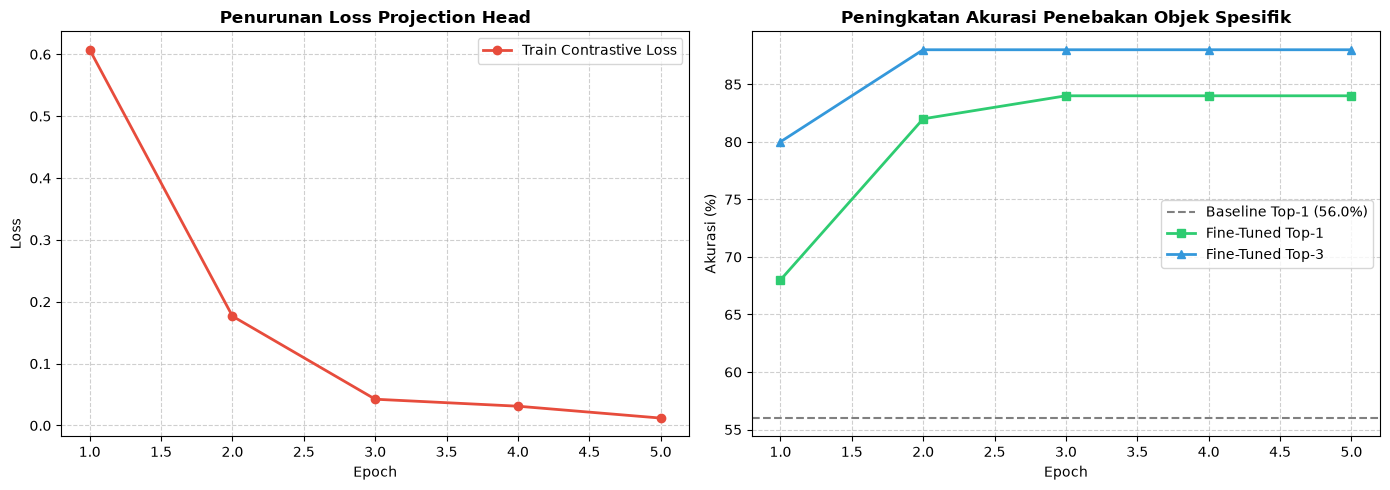

Grafik tersimpan di: experiment_results/sesi_3_projection_head\perbandingan_retrieval_sesi_3.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(history['epoch'], history['train_loss'], marker='o', color='#e74c3c', linewidth=2, label='Train Contrastive Loss')
axes[0].set_title('Penurunan Loss Projection Head', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Plot Akurasi Penebakan Objek Top-1 & Top-3
axes[1].axhline(y=base_metrics['top1'], color='gray', linestyle='--', label=f"Baseline Top-1 ({base_metrics['top1']:.1f}%)")
axes[1].plot(history['epoch'], history['top1_retrieval'], marker='s', color='#2ecc71', linewidth=2, label='Fine-Tuned Top-1')
axes[1].plot(history['epoch'], history['top3_retrieval'], marker='^', color='#3498db', linewidth=2, label='Fine-Tuned Top-3')
axes[1].set_title('Peningkatan Akurasi Penebakan Objek Spesifik', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Akurasi (%)')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plot_path = os.path.join(EXPERIMENT_DIR, "perbandingan_retrieval_sesi_3.png")
plt.tight_layout()
plt.savefig(plot_path, dpi=300)
plt.show()
print(f"Grafik tersimpan di: {plot_path}")

--- 
## 8. Simpan Bobot Model Fine-Tuned Sesi 3

In [8]:
SAVE_DIR = os.path.join(EXPERIMENT_DIR, "model_clip_dormiy_sesi3")
model.save_pretrained(SAVE_DIR)
processor.save_pretrained(SAVE_DIR)
print(f"✅ Model Fine-Tuned Sesi 3 berhasil disimpan di: {SAVE_DIR}/")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

✅ Model Fine-Tuned Sesi 3 berhasil disimpan di: experiment_results/sesi_3_projection_head\model_clip_dormiy_sesi3/
